# Qué recibe el modelo

Esta notebook no entrena. Muestra, en una toma real, cuál es el ejemplo y qué parte de la toma es útil.

La grabación dura cerca de 1 o 2 segundos. Eso no entra como un solo vector. El plan corta la toma en ventanas de 30 ms, con solape. Cada ventana es un ejemplo. Todas las ventanas de una misma toma quedan en la misma partición y heredan la clase del archivo.

El tiempo de la ventana útil es esos 30 ms. A 16 000 Hz la cuenta es `16000 × 0,030 = 480` muestras. El lugar dentro del archivo sale del pico: el bloque de 10 ms con mayor RMS. La ventana se centra en ese pico, `inicio = pico − 480 / 2`, y el tiempo es `inicio / 16000` hasta `inicio / 16000 + 0,030`.

En un parche o un anillo, la ventana útil es la que cae sobre el golpe. Una ventana de silencio, dentro del mismo archivo, llevaría la misma etiqueta y no describe el golpe. En ambiente, la parte útil es un tramo estable, sin un golpe aislado.

El espectrograma de los 2 segundos tampoco es un ejemplo. Es la secuencia de esas ventanas. Una MLP vería una sola ventana. Una CNN vería unas pocas ventanas seguidas, un recorte de ese espectrograma. La etapa 4 elige la representación: las 480 muestras, el espectro de esa ventana, el banco Mel o los MFCC. En la placa el audio no entra crudo. El candidato que sigue hacia el firmware es el espectro, después compactado.

El salto entre ventanas todavía no está elegido. Acá se usa 256 muestras, 16 ms, solo para contar cuántos ejemplos salen de la toma y para dibujar el recorte. Cambiá `ARCHIVO` para ver otra toma. El kernel es el Python de `tinyml`.


In [4]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

FRECUENCIA_HZ = 16000
TIEMPO_UTIL_S = 0.030
VENTANA = int(FRECUENCIA_HZ * TIEMPO_UTIL_S)
N_FFT = 512
SALTO = 256
ARCHIVO = "grabacion/parche/outputs/parche-01.raw"


def resolver(texto):
    ruta = Path(texto)
    if ruta.is_file():
        return ruta
    desde_pruebas = Path("pruebas_py") / texto
    if desde_pruebas.is_file():
        return desde_pruebas
    raise FileNotFoundError(texto)


def indice_pico(pcm):
    paso = int(0.010 * FRECUENCIA_HZ)
    x = pcm.astype(np.float64)
    n = 1 + (x.size - 1) // paso
    mejor_i = 0
    mejor = -1.0
    for i in range(n):
        seg = x[i * paso : (i + 1) * paso]
        valor = float(np.sqrt(np.mean(seg ** 2))) if seg.size else 0.0
        if valor > mejor:
            mejor = valor
            mejor_i = i * paso
    return mejor_i


def recortar(inicio, n):
    inicio = int(inicio)
    if inicio < 0:
        inicio = 0
    if inicio > n - VENTANA:
        inicio = n - VENTANA
    return inicio


ruta = resolver(ARCHIVO)
pcm = np.fromfile(ruta, dtype="<i2")
pico = indice_pico(pcm)
inicio_calculado = pico - VENTANA // 2
golpe = recortar(inicio_calculado, pcm.size)
antes = recortar(golpe - VENTANA - int(0.080 * FRECUENCIA_HZ), pcm.size)
despues = recortar(golpe + VENTANA + int(0.200 * FRECUENCIA_HZ), pcm.size)
cortes = (
    ("antes del golpe", antes),
    ("ventana del golpe", golpe),
    ("despues del golpe", despues),
)
n_ejemplos = 1 + (pcm.size - VENTANA) // SALTO

print("archivo:", ruta)
print("muestras del archivo:", pcm.size)
print("duracion_s:", round(pcm.size / FRECUENCIA_HZ, 3))
print("tiempo de la ventana util_s:", TIEMPO_UTIL_S)
print(
    "calculo: %d * %.3f = %d muestras"
    % (FRECUENCIA_HZ, TIEMPO_UTIL_S, VENTANA)
)
print("pico_muestra:", pico)
print("pico_s:", round(pico / FRECUENCIA_HZ, 3))
print(
    "inicio = %d - %d / 2 = %d"
    % (pico, VENTANA, inicio_calculado)
)
print(
    "ventana util: %.3f s a %.3f s"
    % (golpe / FRECUENCIA_HZ, (golpe + VENTANA) / FRECUENCIA_HZ)
)
print("ejemplos con salto de", SALTO, ":", n_ejemplos)


archivo: grabacion\parche\outputs\parche-01.raw
muestras del archivo: 26420
duracion_s: 1.651
tiempo de la ventana util_s: 0.03
calculo: 16000 * 0.030 = 480 muestras
pico_muestra: 11360
pico_s: 0.71
inicio = 11360 - 480 / 2 = 11120
ventana util: 0.695 s a 0.725 s
ejemplos con salto de 256 : 102


## Tres ventanas de la misma toma

Arriba está el archivo completo, con las tres ventanas de 480 muestras. En el medio, esas ventanas solas: eso es el audio que entra en un ejemplo. Abajo, el espectro de cada una. La escala en dB usa el pico del golpe, así el silencio se ve bajo.

La ventana del golpe concentra la energía. La de antes y la de después, en esta toma, no describen el golpe aunque el archivo se llame parche.


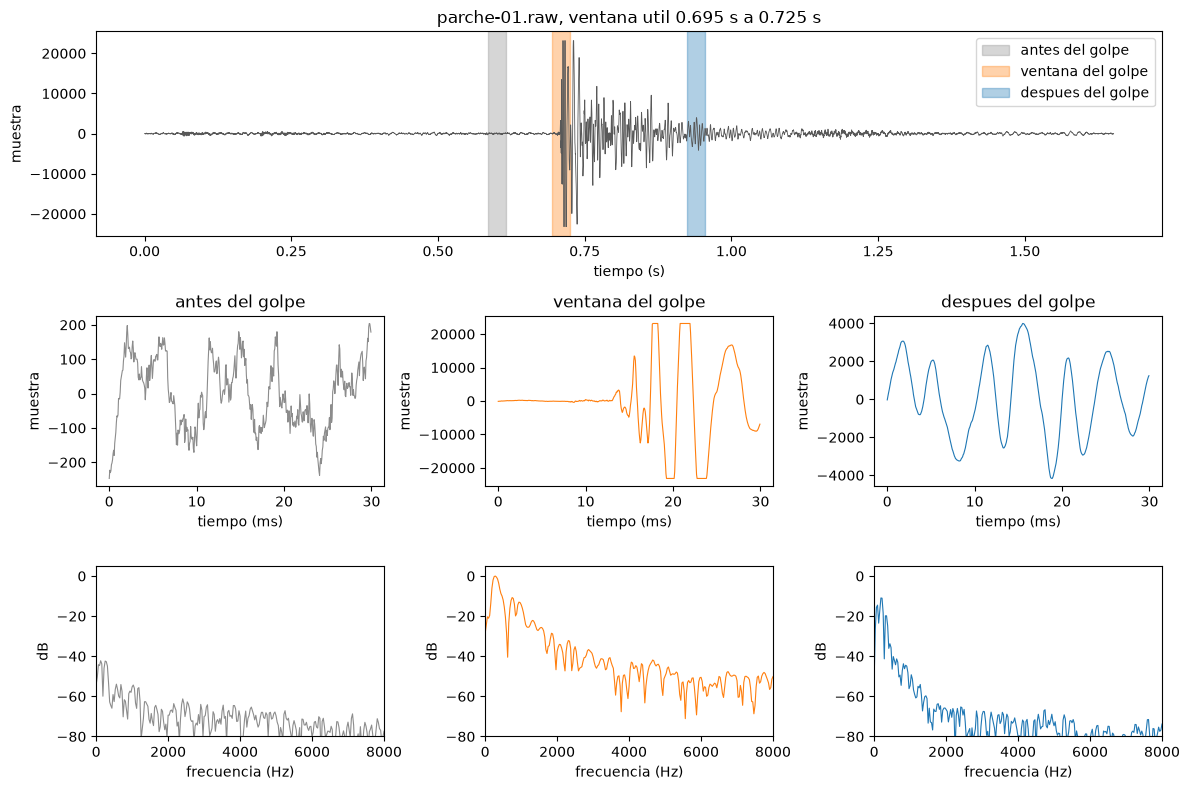

In [5]:
def espectro(muestras):
    seg = muestras.astype(np.float64)
    seg = seg * np.hanning(seg.size)
    return np.abs(np.fft.rfft(seg, n=N_FFT)) ** 2


frecuencias = np.fft.rfftfreq(N_FFT, d=1.0 / FRECUENCIA_HZ)
potencias = [espectro(pcm[inicio : inicio + VENTANA]) for _, inicio in cortes]
referencia = potencias[1].max()
colores = ("0.55", "C1", "C0")
tiempo = np.arange(pcm.size) / FRECUENCIA_HZ

fig = plt.figure(figsize=(12, 8))
rejilla = fig.add_gridspec(3, 3, height_ratios=(1.2, 1.0, 1.0))
ax_todo = fig.add_subplot(rejilla[0, :])
ax_todo.plot(tiempo, pcm, color="0.35", linewidth=0.6)
for (titulo, inicio), color in zip(cortes, colores):
    t0 = inicio / FRECUENCIA_HZ
    t1 = (inicio + VENTANA) / FRECUENCIA_HZ
    ax_todo.axvspan(t0, t1, color=color, alpha=0.35, label=titulo)
ax_todo.set_xlabel("tiempo (s)")
ax_todo.set_ylabel("muestra")
ax_todo.set_title(
    "%s, ventana util %.3f s a %.3f s"
    % (ruta.name, golpe / FRECUENCIA_HZ, (golpe + VENTANA) / FRECUENCIA_HZ)
)
ax_todo.legend(loc="upper right")

for col, ((titulo, inicio), color, potencia) in enumerate(zip(cortes, colores, potencias)):
    seg = pcm[inicio : inicio + VENTANA]
    t_ms = np.arange(VENTANA) * 1000.0 / FRECUENCIA_HZ
    ax_w = fig.add_subplot(rejilla[1, col])
    ax_w.plot(t_ms, seg, color=color, linewidth=0.8)
    ax_w.set_title(titulo)
    ax_w.set_xlabel("tiempo (ms)")
    ax_w.set_ylabel("muestra")
    db = 10.0 * np.log10(potencia / referencia + 1e-12)
    ax_s = fig.add_subplot(rejilla[2, col])
    ax_s.plot(frecuencias, db, color=color, linewidth=0.8)
    ax_s.set_xlim(0, FRECUENCIA_HZ / 2)
    ax_s.set_ylim(-80, 5)
    ax_s.set_xlabel("frecuencia (Hz)")
    ax_s.set_ylabel("dB")

fig.tight_layout()
plt.show()


## Recorte alrededor del golpe

Cinco ventanas seguidas, separadas por el salto de 256 muestras. Cada columna es el espectro de una ventana. Una CNN miraría esta matriz chica. Una MLP miraría una sola columna. El espectrograma de toda la toma es más ancho: incluye el silencio de antes y el final.


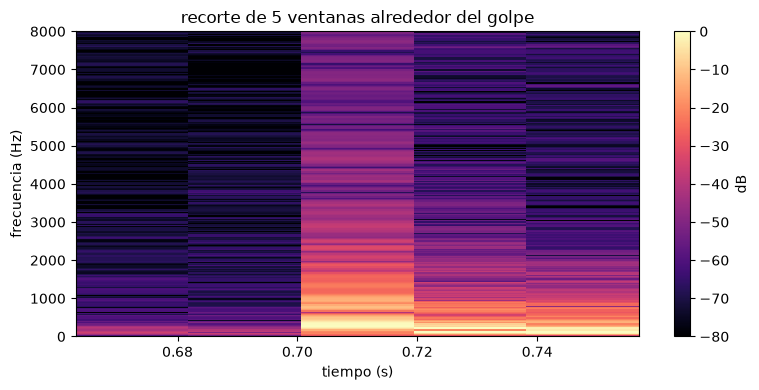

forma de la matriz: ventanas 5 bins 257


In [6]:
n_columnas = 5
centro = n_columnas // 2
columnas = []
for k in range(n_columnas):
    inicio = recortar(golpe + (k - centro) * SALTO, pcm.size)
    columnas.append(espectro(pcm[inicio : inicio + VENTANA]))
matriz = np.stack(columnas, axis=1)
db = 10.0 * np.log10(matriz / referencia + 1e-12)
t0 = (golpe - centro * SALTO) / FRECUENCIA_HZ
t1 = t0 + ((n_columnas - 1) * SALTO + VENTANA) / FRECUENCIA_HZ

fig, ax = plt.subplots(figsize=(8, 4))
imagen = ax.imshow(
    db,
    origin="lower",
    aspect="auto",
    extent=[t0, t1, 0, FRECUENCIA_HZ / 2],
    vmin=-80,
    vmax=0,
    cmap="magma",
    interpolation="nearest",
)
ax.set_xlabel("tiempo (s)")
ax.set_ylabel("frecuencia (Hz)")
ax.set_title("recorte de %d ventanas alrededor del golpe" % n_columnas)
fig.colorbar(imagen, ax=ax, label="dB")
fig.tight_layout()
plt.show()
print("forma de la matriz: ventanas", matriz.shape[1], "bins", matriz.shape[0])
